# 项目：天气识别--优化二
在2中完成了kaggle五分类数据集训练，性能大幅提升

当前方案其实已经包含了迁移学习（使用 ImageNet 预训练的 ResNet50）和基础数据增强（水平翻转、颜色抖动）

最终把准确率从 50% 提升到了 88.25%，在这一版中提升到0.9066！

为了对比性能，我们此次只在同一数据集上进行训练

优化方式二：

1.学习率调整
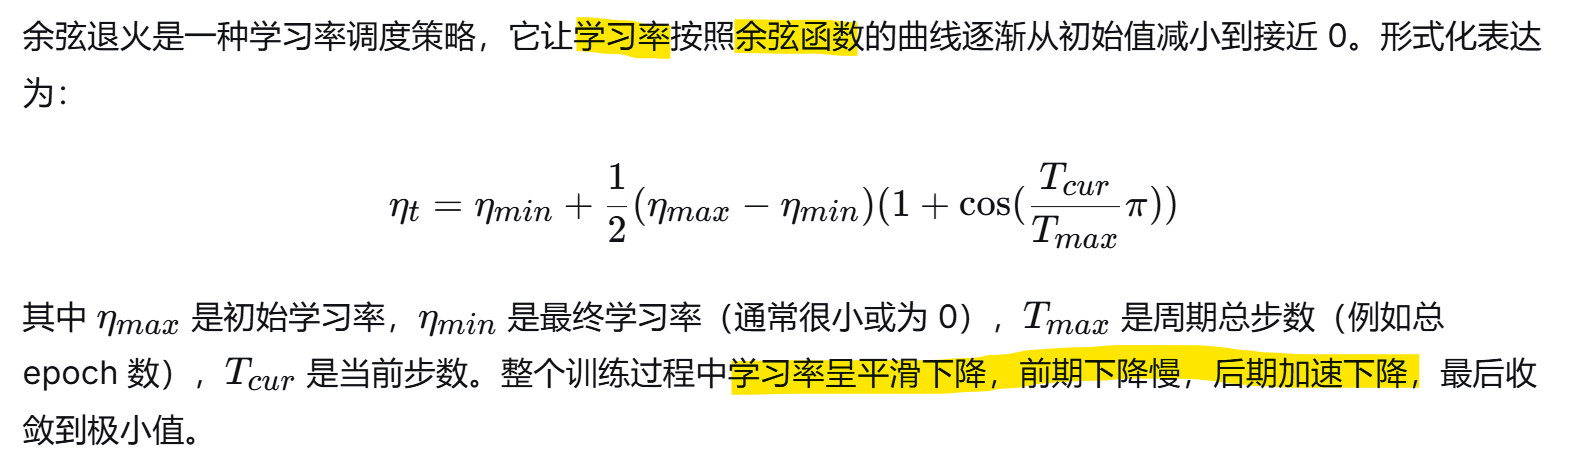

    预期提升效果：
    
    准确率提升：对于分类任务，从阶梯式或 ReduceOnPlateau 切换到余弦退火通常能带来 0.5% ~ 2% 的绝对准确率提升

    收敛速度与稳定性：训练曲线会更平滑，验证损失的方差往往变小，不易出现 epoch 间剧烈波动（如上一版日志中 Epoch 11 验证准确率从 86.8% 掉到 85.4% 的情况会减少）。

    对过拟合的抑制：余弦退火配合强正则化（如 AdamW + 数据增强），能引导模型进入更宽广的极小值，从而提高泛化能力。
    
 2.数据增强
 
 删掉了v3里面缩放、擦除的部分，保留了颜色改变、旋转的部分

# 第一部分：环境准备与数据集自定义

In [ ]:
import os
import paddle
import paddle.vision.transforms as T
from paddle.io import Dataset, DataLoader, random_split
from PIL import Image

# 数据集根目录（请根据你的实际路径修改）
data_dir = 'wholedata'

# ==================== 1. 定义数据预处理 ====================
train_transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(prob=0.5),          # 注意：Paddle 中用 prob
    T.RandomRotation(15),                  # 旋转 ±15 度————保留一个这个！
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


val_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ==================== 2. 自定义数据集类 ====================
class CustomImageDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        super().__init__()
        self.root_dir = root_dir
        self.transform = transform
        
        # 获取所有子文件夹名称并排序
        self.classes = sorted([d for d in os.listdir(root_dir) 
                               if os.path.isdir(os.path.join(root_dir, d))])
        self.class_to_idx = {cls_name: idx for idx, cls_name in enumerate(self.classes)}
        
        # 定义支持的图片后缀
        self.valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff')
        
        # 递归收集图片路径及标签
        self.samples = []
        for class_name in self.classes:
            class_dir = os.path.join(root_dir, class_name)
            class_idx = self.class_to_idx[class_name]
            for root, dirs, files in os.walk(class_dir):
                for filename in files:
                    if filename.lower().endswith(self.valid_extensions):
                        filepath = os.path.join(root, filename)
                        self.samples.append((filepath, class_idx))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label
# ==================== 3. 实例化数据集并划分 ====================
# 加载完整数据集（不带 transform，因为训练/验证需要不同增强）
full_dataset = CustomImageDataset(data_dir)

# 打印类别信息
print("类别列表:", full_dataset.classes)
print("类别映射:", full_dataset.class_to_idx)

# 划分训练集和验证集（80% 训练，20% 验证）
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_subset, val_subset = random_split(full_dataset, [train_size, val_size])

# 因为 random_split 返回的是 Subset 对象，我们需要包装一层以应用不同的 transform
class TransformSubset(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, label = self.subset[idx]   # subset 返回 (img, label)
        if self.transform:
            img = self.transform(img)
        return img, label

train_dataset = TransformSubset(train_subset, train_transform)
val_dataset = TransformSubset(val_subset, val_transform)

# ==================== 4. 创建 DataLoader ====================
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print(f"训练样本数: {len(train_dataset)}，验证样本数: {len(val_dataset)}")

# 第二部分：模型定义、训练与验证
这部分加载预训练 ResNet50，正确替换全连接层为 5 类输出，并定义训练循环。

In [ ]:
import paddle
import paddle.nn.functional as F
from paddle.vision.models import resnet50
from paddle.optimizer.lr import ReduceOnPlateau

print("GPU可用:", paddle.is_compiled_with_cuda())
paddle.set_device('gpu')

# ==================== 1. 构建模型 ====================
model = resnet50(pretrained=True)

# 关键：直接使用 ResNet50 的标准输出维度 2048 来替换全连接层
model.fc = paddle.nn.Linear(2048, 5)

# 验证替换是否正确
print("当前 fc 层:", model.fc)
print("fc 权重形状:", model.fc.weight.shape)   # 应为 [5, 2048]

# ==================== 2. 定义损失函数和优化器 ====================
criterion = paddle.nn.CrossEntropyLoss()  #损失函数没变，要保留它
#optimizer = paddle.optimizer.Adam(learning_rate=0.001, parameters=model.parameters())

# 原方案（ReduceOnPlateau）
# scheduler = paddle.optimizer.lr.ReduceOnPlateau(learning_rate=0.001, factor=0.5, patience=3)

# v3-新方案：余弦退火（从 0.001 衰减到 0），周期为总 epochs 数
#-------------------------v3-结合学习率预热（Warmup）
from paddle.optimizer.lr import LinearWarmup

epochs = 15

cosine_scheduler = paddle.optimizer.lr.CosineAnnealingDecay(
    learning_rate=0.001,
    T_max=epochs - 3,      # 预热 3 个 epoch 后的余弦周期
    eta_min=1e-6
)

scheduler = LinearWarmup(
    learning_rate=cosine_scheduler,
    warmup_steps=3 * len(train_loader),  # 3个epoch的步数（total batches）
    start_lr=1e-5,
    end_lr=0.001
)

# v3-然后创建优化器时传入 scheduler
optimizer = paddle.optimizer.AdamW(
    learning_rate=scheduler,
    weight_decay=0.01,
    parameters=model.parameters()
)

# ==================== 3. 训练与验证循环 ====================
epochs = 15
best_val_acc = 0.0

for epoch in range(epochs):
    # ---------- 训练阶段 ----------
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    
    for batch_id, (images, labels) in enumerate(train_loader):
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        optimizer.clear_grad()
        
        # 统计准确率
        preds = paddle.argmax(outputs, axis=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.shape[0]
        train_loss += loss.item() * labels.shape[0]
        
        if batch_id % 10 == 0:
            print(f"Epoch [{epoch+1}/{epochs}] Batch [{batch_id}] Loss: {loss.item():.4f}")
    
    train_acc = train_correct / train_total
    avg_train_loss = train_loss / train_total
    
    # ---------- 验证阶段 ----------
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with paddle.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            preds = paddle.argmax(outputs, axis=1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.shape[0]
            val_loss += loss.item() * labels.shape[0]
    
    val_acc = val_correct / val_total
    avg_val_loss = val_loss / val_total
    
    # 打印 epoch 统计信息
    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {avg_train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {avg_val_loss:.4f} Acc: {val_acc:.4f}")
    
    # v3-学习率调度——每个 epoch 结束时调用
    scheduler.step()
    
    # 保存最佳模型
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        paddle.save(model.state_dict(), "best_weather_model.pdparams")
        print(f"*** 保存最佳模型，验证准确率: {val_acc:.4f} ***")

print(f"训练完成，最佳验证准确率: {best_val_acc:.4f}")

### 两种策略的技术本质对比：

**ReduceOnPlateau **是一种依赖验证指标的调度器：它监视验证损失，当损失连续若干个 epoch 不再下降时，就自动降低学习率。

因此v2训练循环中必须传入当前 epoch 的验证损失

而**余弦退火**是时间驱动（或步数驱动）的调度器，它的学习率变化仅**取决于当前迭代到了第几个 step**，跟模型表现没有关系。因此只需要调用无参数的 scheduler.step() 即可。


### 通过输出发现的问题：

之前的模型是欠拟合或恰拟合，而现在的模型是过拟合（train的loss很小了，但是test的还是比较大）。目标应该是找到一个更好的平衡

任何能大幅降低训练 loss 的技术（更强模型、更长训练、更精细学习率调整）如果没有相应的正则化配合，都会带来过拟合风险

模型能力足够（甚至过剩），但泛化不足

# 第三部分：推理示例（可选）
训练完成后，你可以使用以下代码对单张图片进行预测。

In [ ]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import paddle
import paddle.nn.functional as F
import os  # 添加os模块

def predict_and_show(model, class_names, transform, img_paths):
    """
    对多张图片进行预测，并在一行中显示原图、预测结果和置信度
    model: 训练好的模型
    class_names: 类别名称列表
    transform: 验证集用的transform
    img_paths: 图片路径列表
    """
    model.eval()
    n = len(img_paths)
    
    # 创建画布，一行显示多张
    fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
    if n == 1:
        axes = [axes]  # 确保axes可迭代
    
    for idx, (img_path, ax) in enumerate(zip(img_paths, axes)):
        # 加载图片
        image = Image.open(img_path).convert('RGB')
        image_tensor = transform(image).unsqueeze(0)
        
        # 预测
        with paddle.no_grad():
            output = model(image_tensor)
            prob = F.softmax(output, axis=1)
            pred_idx = paddle.argmax(prob, axis=1).item()
            confidence = prob[0][pred_idx].item()
        
        pred_class = class_names[pred_idx]
        
        # 从文件名获取真实类别（去掉扩展名）
        # 例如 'evening.png' -> 'evening'
        real_class = os.path.splitext(os.path.basename(img_path))[0]
        
        # 显示原图
        ax.imshow(image)
        ax.axis('off')
        
        # 标题：真实类别 + 预测结果
        color = 'green' if pred_class == real_class else 'red'
        ax.set_title(f'true label: {real_class}\npred label: {pred_class}\nconfidence: {confidence:.2%}', 
                     fontsize=12, color=color)
    
    plt.tight_layout()
    plt.show()


# ==================== 使用 ====================
# 定义要测试的图片路径（支持相对路径）
test_images = [
    'tearcity.png',
    'yssunny.png',
    'mcsnow.jpg'
    
]

predict_and_show(model, full_dataset.classes, val_transform, test_images)

In [ ]:
# 1. 导入库
import paddle
from paddle.vision.models import resnet50

# 2. 重新创建模型结构
model = resnet50(pretrained=False)
model.fc = paddle.nn.Linear(in_features=2048, out_features=5)

# 3. 加载保存的模型参数
model.set_state_dict(paddle.load("best_weather_model.pdparams"))
model.eval()

print("模型加载成功！")# 4. 定义transform（和训练时一样）
import paddle.vision.transforms as T
val_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
# 5. 预测
from PIL import Image
import matplotlib.pyplot as plt
import paddle.nn.functional as F

def predict(img_path):
    image = Image.open(img_path).convert('RGB')
    image_tensor = val_transform(image).unsqueeze(0)
    
    with paddle.no_grad():
        output = model(image_tensor)
        prob = F.softmax(output, axis=1)
        pred_idx = paddle.argmax(prob, axis=1).item()
        confidence = prob[0][pred_idx].item()
    
    return ['cloudy', 'foggy', 'rainy', 'snowy', 'sunny'][pred_idx], confidence

# 测试
predict('wholedata/cloudy/cloudy/261443.jpg')

### 结果分析：

使用余弦退火+warmup预热——核心代码修改如下：

```
from paddle.optimizer.lr import LinearWarmup

# 内部余弦调度器，预热 3 个 epoch 后剩余 epoch 用余弦衰减
cosine_scheduler = paddle.optimizer.lr.CosineAnnealingDecay(
    learning_rate=0.001,
    T_max=epochs - 3,    # 剩余 12 个 epoch 完成余弦周期
    eta_min=1e-6
)

# 预热包装，warmup_steps 设为 3，表示前 3 次步进（即前 3 个 epoch）线性增加
scheduler = LinearWarmup(
    learning_rate=cosine_scheduler,
    warmup_steps=3,      # 因为每个 epoch 调用一次，所以 3 表示 3 个 epoch
    start_lr=1e-5,
    end_lr=0.001
)

optimizer = paddle.optimizer.AdamW(
    learning_rate=scheduler,
    weight_decay=0.01,
    parameters=model.parameters()
)
```

性能提升，一开始性能提升比起v3快很多

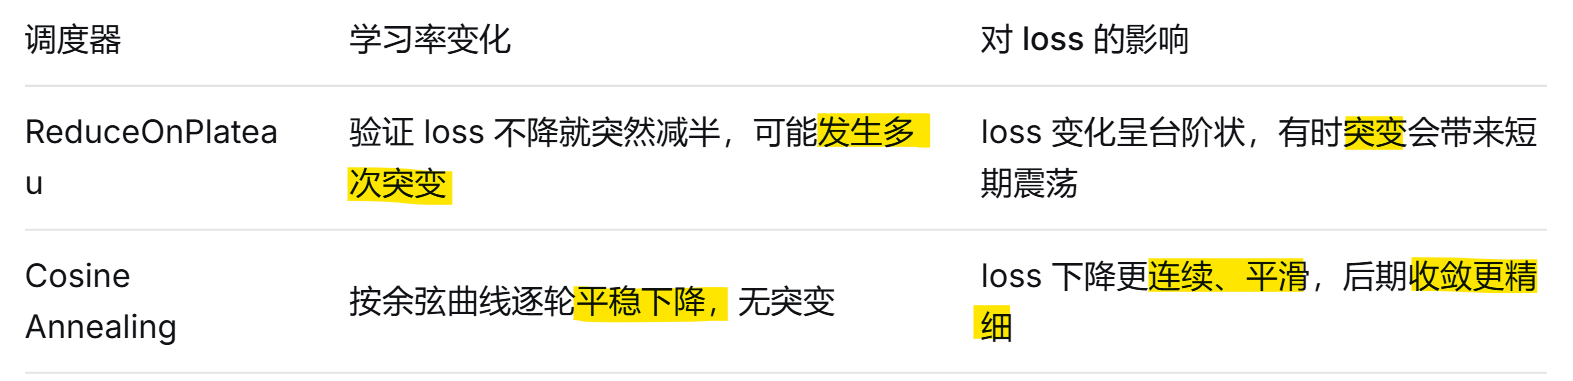


### 改进方向：

现在的状态是模型能力足够（甚至过剩），但泛化不足。调整策略应该是：

1.加入 RandomResizedCrop 和 RandomErasing（不改学习率），再训练 15-20 个 epoch，观察验证 loss 是否同步下降。

2.设置早停：当验证 loss 连续 3 个 epoch 不降时停止训练，保存最佳模型。

经过这些调整后，训练 loss 可能会从 0.08 回升到 0.2 左右